# 24 · Watershed on Real Pills

LRT4012 Robot Vision · Fall 2026


## Markers separate touching foreground regions

A distance transform assigns each foreground pixel its distance to the nearest background pixel. Peaks can seed object markers. Watershed grows labeled markers across the image; unknown pixels start at label zero, background is label one, and boundaries become minus one. A missing seed merges objects; extra seeds can split a single object.

For a foreground distance image $D$, the seed rule is $D>\alpha\max(D)$, where $\alpha\in(0,1)$ is a relative threshold. This global rule is a controlled baseline and may fail for objects of unequal size. Count error is $|\hat n-n|$, where $\hat n$ is predicted object count and $n$ is the reference count. Accurate count alone does not prove accurate boundaries.


In [1]:
from pathlib import Path
import os, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repository():
    candidates = []
    if os.environ.get('VISION_ROBOTICA_REPO'):
        candidates.append(Path(os.environ['VISION_ROBOTICA_REPO']).expanduser())
    candidates += [Path.cwd(), *Path.cwd().parents]
    for root in candidates:
        if (root / 'requirements.txt').is_file() and (root / 'imagenes').is_dir():
            return root.resolve()
    raise FileNotFoundError('Open Jupyter inside the course repository, or set VISION_ROBOTICA_REPO to its root.')

REPO = find_repository()
IMAGE_DIR = REPO / 'imagenes'  # Read-only official resources.
# Save your own notebook and generated images in student_work/ and student_work/imagenes/.
cv2.setRNGSeed(4012)
cv2.setNumThreads(1)
rng = np.random.default_rng(4012)
plt.rcParams.update({'figure.dpi':100, 'font.size':10})

def load_image(name, max_side=640):
    image = cv2.imread(str(IMAGE_DIR / name), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f'Official resource could not be read: {name}')
    h, w = image.shape[:2]
    if max(h, w) > max_side:
        scale = max_side / max(h, w)
        image = cv2.resize(image, (round(w*scale), round(h*scale)), interpolation=cv2.INTER_AREA)
    return image

def gray(image): return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

def panels(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4*len(images), 3.5), squeeze=False)
    for ax, im, title in zip(axes[0], images, titles):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    plt.show()

def timed_ms(fn, repetitions=30):
    fn()  # Warm-up.
    times = []
    for _ in range(repetitions):
        start = time.perf_counter()
        fn()
        times.append((time.perf_counter()-start)*1000)
    return float(np.median(times))

def mask_metrics(prediction, reference):
    a, b = prediction.astype(bool), reference.astype(bool)
    tp = int(np.count_nonzero(a & b))
    fp = int(np.count_nonzero(a & ~b))
    fn = int(np.count_nonzero(~a & b))
    return {'IoU': tp/(tp+fp+fn) if tp+fp+fn else 1.0,
            'precision': tp/(tp+fp) if tp+fp else np.nan,
            'recall': tp/(tp+fn) if tp+fn else np.nan,
            'F1': 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 1.0}


In [2]:
def watershed_objects(image,mask,alpha=0.55):
    distance=cv2.distanceTransform(mask,cv2.DIST_L2,5)
    seeds=np.uint8(distance>alpha*distance.max()) if distance.max()>0 else np.zeros_like(mask)
    _,seed_labels=cv2.connectedComponents(seeds)
    background=cv2.dilate(mask,np.ones((3,3),np.uint8),iterations=2)
    markers=seed_labels.astype(np.int32)+1
    markers[(background>0)&(seeds==0)]=0
    result=cv2.watershed(image.copy(),markers)
    ids=[int(i) for i in np.unique(result) if i>1 and np.any((result==i)&(mask>0))]
    drawing=image.copy(); drawing[result==-1]=(255,0,255)
    return result,ids,seeds,drawing


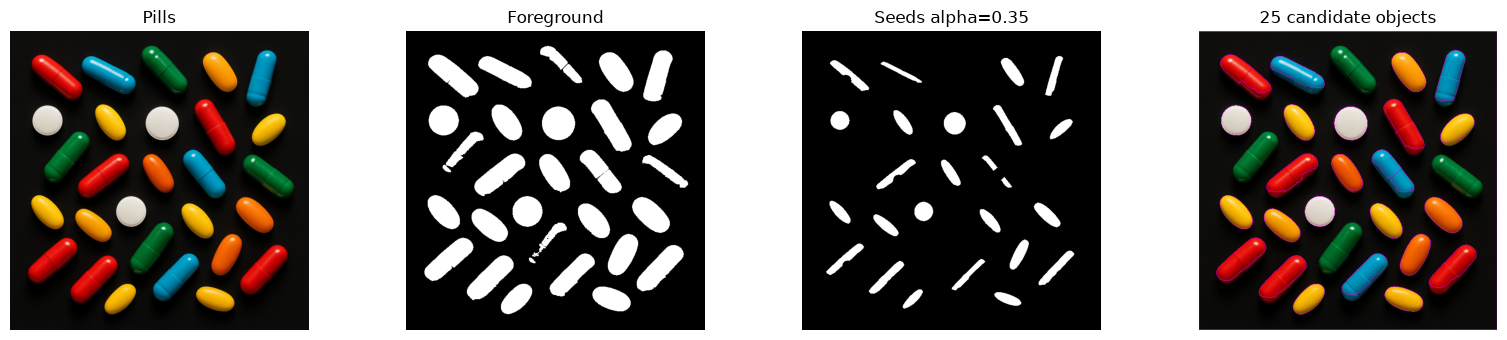

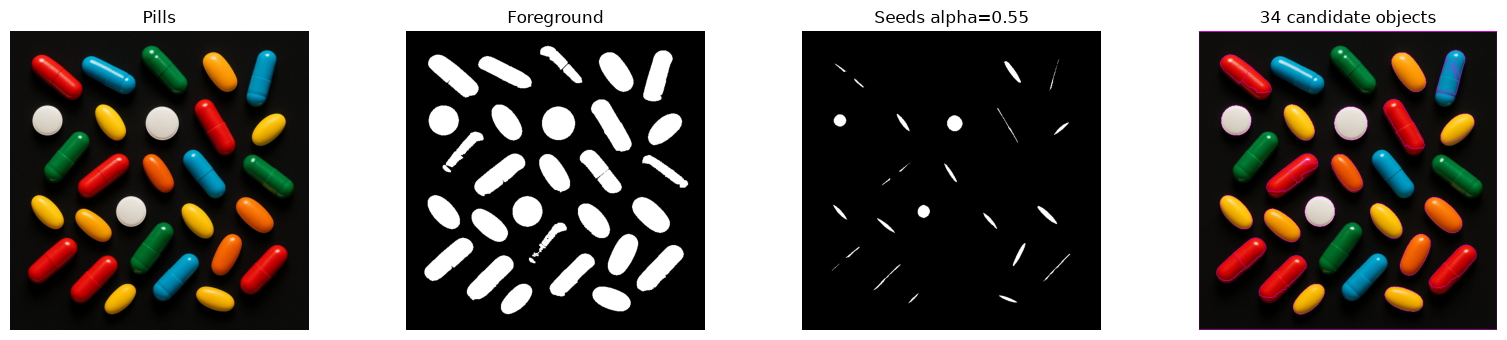

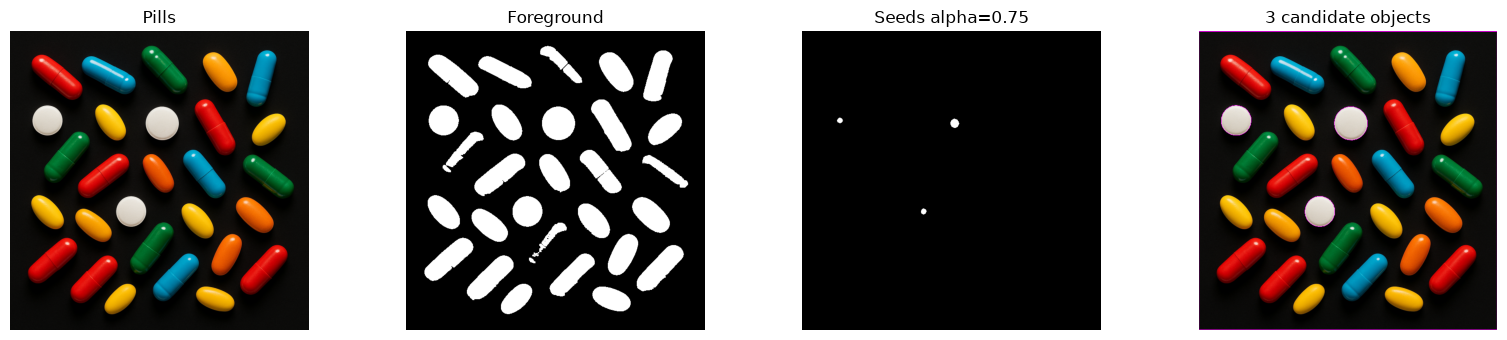

,alpha,candidate_objects,seed_components
0,0.35,25,25
1,0.55,34,34
2,0.75,3,3


In [3]:
image=load_image('pildoras2.png')
# Bright objects on a dark background: threshold Value with positive polarity.
g=cv2.cvtColor(image,cv2.COLOR_BGR2HSV)[:,:,2]
_,mask=cv2.threshold(g,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,np.ones((3,3),np.uint8))
rows=[]
for alpha in [0.35,0.55,0.75]:
    labels,ids,seeds,drawing=watershed_objects(image,mask,alpha)
    rows.append({'alpha':alpha,'candidate_objects':len(ids),'seed_components':cv2.connectedComponents(seeds)[0]-1})
    panels([image,mask,seeds*255,drawing],['Pills','Foreground',f'Seeds alpha={alpha}',f'{len(ids)} candidate objects'])
display(pd.DataFrame(rows))


## Manual validation

Count visible objects independently and record how occlusions or image-border objects are treated. Add this reference count to the table before reporting count error. Examine merged, split and missing instances; do not choose the reference count to match the algorithm.


## Robotic interpretation

Choose a marker setting for inspection and justify every remaining count discrepancy. Identify whether an error comes from the foreground mask or the marker stage. Consider variable pill size and specular reflections.


## References

- [OpenCV: thresholding](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html)
- [OpenCV: watershed](https://docs.opencv.org/4.13.0/d3/db4/tutorial_py_watershed.html)
- [OpenCV: contours](https://docs.opencv.org/4.x/d3/d05/tutorial_py_table_of_contents_contours.html)
